In [7]:
import numpy as np
import matplotlib.pyplot as plt

from scipy.signal import convolve
import time
import pandas as pd

In [8]:
def apply_channel_fse(
    symbols,
    channel,
    samples_per_symbol,
    snr_db,
    fse_samples_per_symbol=2
):
    """
    Generate received samples for a fractionally-spaced equalizer.
    """

    # Oversample transmitted PAM4 symbols
    tx_waveform = np.repeat(symbols, samples_per_symbol)

    # Apply channel
    rx_noiseless = convolve(
        tx_waveform,
        channel,
        mode="same"
    )

    # Calculate noise power
    signal_power = np.mean(rx_noiseless ** 2)
    snr_linear = 10 ** (snr_db / 10)
    noise_power = signal_power / snr_linear

    # Add AWGN
    noise = np.random.normal(
        0,
        np.sqrt(noise_power),
        len(rx_noiseless)
    )

    rx_signal = rx_noiseless + noise

    # Select evenly spaced samples
    spacing = samples_per_symbol // fse_samples_per_symbol

    sample_indices = np.arange(
        samples_per_symbol // 2,
        len(rx_signal),
        spacing
    )

    rx_samples = rx_signal[sample_indices]

    return rx_samples

In [9]:
def bits_to_pam4(bits):
    bit_pairs = bits.reshape(-1, 2)

    symbols = np.array([
        pam4_mapping[tuple(pair)]
        for pair in bit_pairs
    ])

    return symbols

In [10]:
samples_per_symbol = 10

pam4_mapping = {
    (0, 0): -3,
    (0, 1): -1,
    (1, 1): 1,
    (1, 0): 3
}

pam4_to_bits = {
    -3: (0, 0),
    -1: (0, 1),
     1: (1, 1),
     3: (1, 0)
}

channel = np.array([0.1, 0.2, 0.5, 0.2, 0.1])

channel_test = np.array([
    0.15,
    0.30,
    0.40,
    0.30,
    0.15
])

channel_test = channel_test / np.sum(channel_test)

print("Test channel:", channel_test)

num_bits = 100_000
snr_db = 15

Test channel: [0.11538462 0.23076923 0.30769231 0.23076923 0.11538462]


In [11]:
def pam4_detect(samples):
    detected = np.zeros(len(samples), dtype=int)

    detected[samples < -2] = -3
    detected[(samples >= -2) & (samples < 0)] = -1
    detected[(samples >= 0) & (samples < 2)] = 1
    detected[samples >= 2] = 3

    return detected

In [12]:
# CNN dataset configuration

NUM_TRAIN_BITS = 200000
NUM_VAL_BITS = 40000
NUM_TEST_BITS = 40000

CNN_SNR_DB = 14
SAMPLES_PER_SYMBOL = 2

In [13]:
def generate_cnn_data(num_bits, snr_db):
    """
    Generate PAM4 communication data for CNN training/testing.

    Returns:
        received: noisy received waveform
        symbols: transmitted PAM4 symbols
        bits: original transmitted bits
    """

    # Generate random bits
    bits = np.random.randint(0, 2, num_bits)

    # Convert bits to PAM4 symbols
    symbols = bits_to_pam4(bits)

    # Pass through the same optical channel
    received = apply_channel_fse(
        symbols,
        channel_test,
        samples_per_symbol,
        snr_db=snr_db,
        fse_samples_per_symbol=2
    )

    return received, symbols, bits

In [14]:
# Generate training data
train_received_cnn, train_symbols_cnn, train_bits_cnn = generate_cnn_data(
    NUM_TRAIN_BITS,
    CNN_SNR_DB
)

# Generate validation data
val_received_cnn, val_symbols_cnn, val_bits_cnn = generate_cnn_data(
    NUM_VAL_BITS,
    CNN_SNR_DB
)

# Generate test data
test_received_cnn, test_symbols_cnn, test_bits_cnn = generate_cnn_data(
    NUM_TEST_BITS,
    CNN_SNR_DB
)

print("Training bits:", len(train_bits_cnn))
print("Validation bits:", len(val_bits_cnn))
print("Test bits:", len(test_bits_cnn))

print("\nTraining symbols:", len(train_symbols_cnn))
print("Validation symbols:", len(val_symbols_cnn))
print("Test symbols:", len(test_symbols_cnn))

Training bits: 200000
Validation bits: 40000
Test bits: 40000

Training symbols: 100000
Validation symbols: 20000
Test symbols: 20000


In [15]:
print("First 10 training symbols:")
print(train_symbols_cnn[:10])

print("\nFirst 20 training bits:")
print(train_bits_cnn[:20])

print("\nFirst 20 received samples:")
print(train_received_cnn[:20])

First 10 training symbols:
[-1 -1 -3  3 -3  3  3  3 -3  1]

First 20 training bits:
[0 1 0 1 0 0 1 0 0 0 1 0 1 0 1 0 0 0 1 1]

First 20 received samples:
[-1.57896088 -0.77466847 -0.39437313 -2.41705754 -1.88914787  0.73834301
  3.0822467  -1.25637097 -3.12428151  0.90840085  3.32667338  2.64963577
  3.22247596  3.04246254  2.36593463 -0.58890192 -3.55384791 -0.39454791
  1.2137752   1.43425665]


In [16]:
def create_cnn_windows(
    received,
    symbols,
    samples_per_symbol=2,
    window_size=5
):
    """
    Create local waveform windows for CNN training.

    Each window contains several received samples
    surrounding one transmitted PAM4 symbol.
    """

    half_window = window_size // 2

    X = []
    y = []

    num_symbols = min(
        len(symbols),
        len(received) // samples_per_symbol
    )

    for n in range(
        half_window,
        num_symbols - half_window
    ):

        # Center window around symbol n
        center = n * samples_per_symbol

        start = center - half_window
        end = center + half_window + 1

        window = received[start:end]

        if len(window) != window_size:
            continue

        X.append(window)
        y.append(symbols[n])

    return np.array(X), np.array(y)

In [17]:
WINDOW_SIZE = 5

X_train, y_train = create_cnn_windows(
    train_received_cnn,
    train_symbols_cnn,
    samples_per_symbol=2,
    window_size=WINDOW_SIZE
)

X_val, y_val = create_cnn_windows(
    val_received_cnn,
    val_symbols_cnn,
    samples_per_symbol=2,
    window_size=WINDOW_SIZE
)

X_test, y_test = create_cnn_windows(
    test_received_cnn,
    test_symbols_cnn,
    samples_per_symbol=2,
    window_size=WINDOW_SIZE
)

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

print("X_val shape:", X_val.shape)
print("y_val shape:", y_val.shape)

print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

X_train shape: (99995, 5)
y_train shape: (99995,)
X_val shape: (19995, 5)
y_val shape: (19995,)
X_test shape: (19995, 5)
y_test shape: (19995,)


In [18]:
def pam4_to_class(symbols):
    class_map = {
        -3: 0,
        -1: 1,
         1: 2,
         3: 3
    }

    return np.array([
        class_map[int(symbol)]
        for symbol in symbols
    ])

In [19]:
y_train_class = pam4_to_class(y_train)
y_val_class = pam4_to_class(y_val)
y_test_class = pam4_to_class(y_test)

print("Original symbols:", y_train[:10])
print("CNN classes:", y_train_class[:10])

Original symbols: [-3  3 -3  3  3  3 -3  1  1  1]
CNN classes: [0 3 0 3 3 3 0 2 2 2]


In [20]:
import torch
from torch.utils.data import TensorDataset, DataLoader

X_train_tensor = torch.tensor(
    X_train,
    dtype=torch.float32
)

X_val_tensor = torch.tensor(
    X_val,
    dtype=torch.float32
)

X_test_tensor = torch.tensor(
    X_test,
    dtype=torch.float32
)

y_train_tensor = torch.tensor(
    y_train_class,
    dtype=torch.long
)

y_val_tensor = torch.tensor(
    y_val_class,
    dtype=torch.long
)

y_test_tensor = torch.tensor(
    y_test_class,
    dtype=torch.long
)

print("X_train tensor:", X_train_tensor.shape)
print("y_train tensor:", y_train_tensor.shape)

X_train tensor: torch.Size([99995, 5])
y_train tensor: torch.Size([99995])


In [21]:
BATCH_SIZE = 256

train_dataset = TensorDataset(
    X_train_tensor,
    y_train_tensor
)

val_dataset = TensorDataset(
    X_val_tensor,
    y_val_tensor
)

test_dataset = TensorDataset(
    X_test_tensor,
    y_test_tensor
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

Training batches: 391
Validation batches: 79
Test batches: 79


In [22]:
device = torch.device(
    "mps" if torch.backends.mps.is_available()
    else "cpu"
)

print("Using device:", device)

Using device: mps


In [24]:
class CNNEqualizer(nn.Module):

    def __init__(self):
        super().__init__()

        self.conv_layers = nn.Sequential(

            nn.Conv1d(
                in_channels=1,
                out_channels=16,
                kernel_size=3,
                padding=1
            ),

            nn.ReLU(),

            nn.Conv1d(
                in_channels=16,
                out_channels=32,
                kernel_size=3,
                padding=1
            ),

            nn.ReLU()
        )

        self.fc_layers = nn.Sequential(

            nn.Flatten(),

            nn.Linear(
                32 * WINDOW_SIZE,
                32
            ),

            nn.ReLU(),

            nn.Linear(
                32,
                4
            )
        )

    def forward(self, x):

        x = self.conv_layers(x)

        x = self.fc_layers(x)

        return x

In [25]:
cnn_model = CNNEqualizer().to(device)

print(cnn_model)

CNNEqualizer(
  (conv_layers): Sequential(
    (0): Conv1d(1, 16, kernel_size=(3,), stride=(1,), padding=(1,))
    (1): ReLU()
    (2): Conv1d(16, 32, kernel_size=(3,), stride=(1,), padding=(1,))
    (3): ReLU()
  )
  (fc_layers): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=160, out_features=32, bias=True)
    (2): ReLU()
    (3): Linear(in_features=32, out_features=4, bias=True)
  )
)


In [27]:
# Loss function
criterion = nn.CrossEntropyLoss()

# Optimizer
optimizer = torch.optim.Adam(
    cnn_model.parameters(),
    lr=0.001
)

print("Loss function:", criterion)
print("Optimizer:", optimizer)

Loss function: CrossEntropyLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


In [28]:
NUM_EPOCHS = 10

train_losses = []
val_losses = []

train_accuracies = []
val_accuracies = []

for epoch in range(NUM_EPOCHS):

    # ==========================
    # Training
    # ==========================

    cnn_model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for X_batch, y_batch in train_loader:

        # Add channel dimension:
        # (batch, 5) → (batch, 1, 5)
        X_batch = X_batch.unsqueeze(1).to(device)
        y_batch = y_batch.to(device)

        # Clear old gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = cnn_model(X_batch)

        # Calculate loss
        loss = criterion(
            outputs,
            y_batch
        )

        # Backpropagation
        loss.backward()

        # Update weights
        optimizer.step()

        # Track statistics
        running_loss += (
            loss.item() * X_batch.size(0)
        )

        predictions = torch.argmax(
            outputs,
            dim=1
        )

        correct += (
            (predictions == y_batch)
            .sum()
            .item()
        )

        total += y_batch.size(0)

    epoch_train_loss = (
        running_loss / total
    )

    epoch_train_accuracy = (
        correct / total
    )

    # ==========================
    # Validation
    # ==========================

    cnn_model.eval()

    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for X_batch, y_batch in val_loader:

            X_batch = X_batch.unsqueeze(1).to(device)
            y_batch = y_batch.to(device)

            outputs = cnn_model(X_batch)

            loss = criterion(
                outputs,
                y_batch
            )

            val_running_loss += (
                loss.item() * X_batch.size(0)
            )

            predictions = torch.argmax(
                outputs,
                dim=1
            )

            val_correct += (
                (predictions == y_batch)
                .sum()
                .item()
            )

            val_total += y_batch.size(0)

    epoch_val_loss = (
        val_running_loss / val_total
    )

    epoch_val_accuracy = (
        val_correct / val_total
    )

    # Store results
    train_losses.append(epoch_train_loss)
    val_losses.append(epoch_val_loss)

    train_accuracies.append(
        epoch_train_accuracy
    )

    val_accuracies.append(
        epoch_val_accuracy
    )

    print(
        f"Epoch {epoch + 1:2d}/{NUM_EPOCHS} | "
        f"Train Loss: {epoch_train_loss:.6f} | "
        f"Train Acc: {epoch_train_accuracy:.4f} | "
        f"Val Loss: {epoch_val_loss:.6f} | "
        f"Val Acc: {epoch_val_accuracy:.4f}"
    )

Epoch  1/10 | Train Loss: 0.154192 | Train Acc: 0.9617 | Val Loss: 0.012771 | Val Acc: 0.9958
Epoch  2/10 | Train Loss: 0.011631 | Train Acc: 0.9965 | Val Loss: 0.010613 | Val Acc: 0.9960
Epoch  3/10 | Train Loss: 0.010557 | Train Acc: 0.9965 | Val Loss: 0.013720 | Val Acc: 0.9953
Epoch  4/10 | Train Loss: 0.010236 | Train Acc: 0.9967 | Val Loss: 0.009908 | Val Acc: 0.9962
Epoch  5/10 | Train Loss: 0.010446 | Train Acc: 0.9965 | Val Loss: 0.010602 | Val Acc: 0.9964
Epoch  6/10 | Train Loss: 0.009950 | Train Acc: 0.9967 | Val Loss: 0.015061 | Val Acc: 0.9945
Epoch  7/10 | Train Loss: 0.010060 | Train Acc: 0.9964 | Val Loss: 0.011432 | Val Acc: 0.9959
Epoch  8/10 | Train Loss: 0.009596 | Train Acc: 0.9967 | Val Loss: 0.010189 | Val Acc: 0.9964
Epoch  9/10 | Train Loss: 0.010111 | Train Acc: 0.9964 | Val Loss: 0.009877 | Val Acc: 0.9960
Epoch 10/10 | Train Loss: 0.009469 | Train Acc: 0.9967 | Val Loss: 0.011930 | Val Acc: 0.9958


In [29]:
cnn_model.eval()

cnn_predictions = []

with torch.no_grad():

    for X_batch, _ in test_loader:

        X_batch = X_batch.unsqueeze(1).to(device)

        outputs = cnn_model(X_batch)

        predictions = torch.argmax(
            outputs,
            dim=1
        )

        cnn_predictions.extend(
            predictions.cpu().numpy()
        )

cnn_predictions = np.array(cnn_predictions)

print("Number of CNN predictions:", len(cnn_predictions))
print("Unique predicted classes:", np.unique(cnn_predictions))

Number of CNN predictions: 19995
Unique predicted classes: [0 1 2 3]


In [30]:
class_to_pam4 = {
    0: -3,
    1: -1,
    2: 1,
    3: 3
}

cnn_predicted_symbols = np.array([
    class_to_pam4[int(c)]
    for c in cnn_predictions
])

print("First 20 CNN predictions:")
print(cnn_predicted_symbols[:20])

print("\nFirst 20 actual symbols:")
print(y_test[:20])

First 20 CNN predictions:
[-3 -1  3 -3 -3 -3 -3  3  3 -3 -1  1  3  3 -3  1  1 -3 -1 -1]

First 20 actual symbols:
[-3 -3  3 -3 -3 -3 -3  3  3 -3 -1  1  3  3 -3  1  1 -3 -1 -1]


In [32]:
def symbols_to_bits(symbols):
    bit_map = {
        -3: [0, 0],
        -1: [0, 1],
         1: [1, 0],
         3: [1, 1]
    }

    bits = []

    for symbol in symbols:
        bits.extend(bit_map[int(symbol)])

    return np.array(bits)

In [33]:
cnn_predicted_bits = symbols_to_bits(
    cnn_predicted_symbols
)

cnn_true_bits = symbols_to_bits(
    y_test
)

bit_errors = np.sum(
    cnn_predicted_bits != cnn_true_bits
)

total_bits = len(cnn_true_bits)

cnn_ber_14db = bit_errors / total_bits

print("========== CNN RESULT ==========")
print("SNR:", CNN_SNR_DB, "dB")
print("Bit errors:", bit_errors)
print("Total bits:", total_bits)
print(f"BER: {cnn_ber_14db:.6f}")

========== CNN RESULT ==========
SNR: 14 dB
Bit errors: 111
Total bits: 39990
BER: 0.002776


In [34]:
cnn_snr_values = np.arange(0, 21, 2)

cnn_ber_results = []

cnn_model.eval()

for snr_db in cnn_snr_values:

    # Generate fresh test data
    bits = np.random.randint(0, 2, 40000)
    symbols = bits_to_pam4(bits)

    received = apply_channel_fse(
        symbols,
        channel_test,
        samples_per_symbol,
        snr_db=snr_db,
        fse_samples_per_symbol=2
    )

    # Create CNN windows
    X_snr, y_snr = create_cnn_windows(
        received,
        symbols,
        samples_per_symbol=2,
        window_size=WINDOW_SIZE
    )

    # Convert to tensor
    X_snr_tensor = torch.tensor(
        X_snr,
        dtype=torch.float32
    )

    # CNN inference
    with torch.no_grad():

        X_snr_tensor = X_snr_tensor.unsqueeze(1).to(device)

        outputs = cnn_model(
            X_snr_tensor
        )

        predictions = torch.argmax(
            outputs,
            dim=1
        ).cpu().numpy()

    # Convert classes → PAM4
    predicted_symbols = np.array([
        class_to_pam4[int(c)]
        for c in predictions
    ])

    # Convert to bits
    predicted_bits = symbols_to_bits(
        predicted_symbols
    )

    true_bits = symbols_to_bits(
        y_snr
    )

    # BER
    bit_errors = np.sum(
        predicted_bits != true_bits
    )

    total_bits = len(true_bits)

    ber = bit_errors / total_bits

    cnn_ber_results.append(ber)

    print(
        f"SNR = {snr_db:2d} dB | "
        f"CNN BER = {ber:.6f}"
    )

SNR =  0 dB | CNN BER = 0.270968
SNR =  2 dB | CNN BER = 0.231283
SNR =  4 dB | CNN BER = 0.181970
SNR =  6 dB | CNN BER = 0.123606
SNR =  8 dB | CNN BER = 0.075344
SNR = 10 dB | CNN BER = 0.035759
SNR = 12 dB | CNN BER = 0.012153
SNR = 14 dB | CNN BER = 0.002401
SNR = 16 dB | CNN BER = 0.000200
SNR = 18 dB | CNN BER = 0.000000
SNR = 20 dB | CNN BER = 0.000000


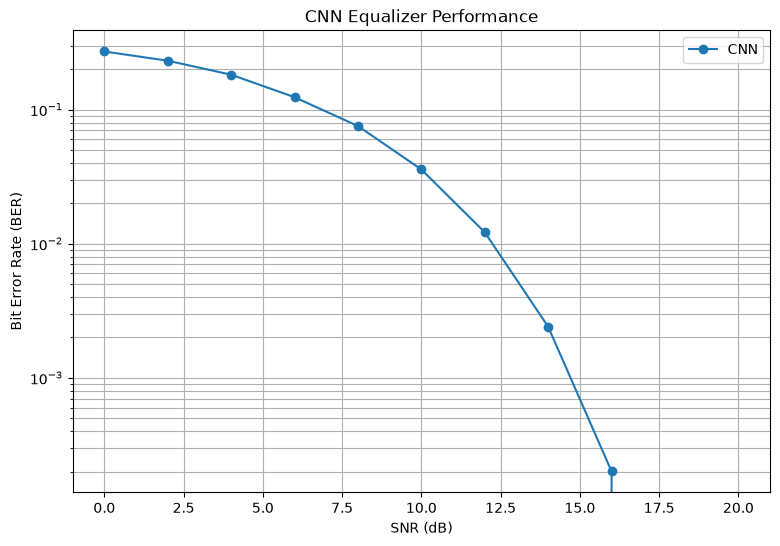

In [35]:
plt.figure(figsize=(9, 6))

plt.semilogy(
    cnn_snr_values,
    cnn_ber_results,
    marker="o",
    label="CNN"
)

plt.xlabel("SNR (dB)")
plt.ylabel("Bit Error Rate (BER)")
plt.title("CNN Equalizer Performance")
plt.grid(True, which="both")
plt.legend()

plt.show()

In [36]:
cnn_num_parameters = sum(
    p.numel()
    for p in cnn_model.parameters()
    if p.requires_grad
)

print("CNN trainable parameters:", cnn_num_parameters)

CNN trainable parameters: 6916


In [37]:
timing_cnn_model = CNNEqualizer().to(device)

timing_criterion = nn.CrossEntropyLoss()

timing_optimizer = torch.optim.Adam(
    timing_cnn_model.parameters(),
    lr=0.001
)

In [38]:
import time

NUM_TIMING_EPOCHS = 10

start_time = time.perf_counter()

for epoch in range(NUM_TIMING_EPOCHS):

    timing_cnn_model.train()

    for X_batch, y_batch in train_loader:

        X_batch = X_batch.unsqueeze(1).to(device)
        y_batch = y_batch.to(device)

        timing_optimizer.zero_grad()

        outputs = timing_cnn_model(
            X_batch
        )

        loss = timing_criterion(
            outputs,
            y_batch
        )

        loss.backward()

        timing_optimizer.step()

end_time = time.perf_counter()

cnn_training_time = end_time - start_time

print(
    f"CNN training time: "
    f"{cnn_training_time:.6f} seconds"
)

CNN training time: 29.013223 seconds


In [40]:
timing_cnn_model.eval()

# Make sure we're not timing data preparation
inference_inputs = X_test_tensor.unsqueeze(1).to(device)

# Warm-up run
with torch.no_grad():
    _ = timing_cnn_model(inference_inputs)

# Actual timing
start_time = time.perf_counter()

with torch.no_grad():
    inference_outputs = timing_cnn_model(
        inference_inputs
    )

end_time = time.perf_counter()

cnn_inference_time = end_time - start_time

print(
    f"CNN inference time: "
    f"{cnn_inference_time:.6f} seconds"
)

CNN inference time: 0.000516 seconds


In [41]:
cnn_results = {
    "Equalizer": "CNN",
    "BER_14dB": cnn_ber_14db,
    "Training_Time_s": cnn_training_time,
    "Inference_Time_s": cnn_inference_time,
    "Num_Parameters": cnn_num_parameters
}

print("========== CNN BENCHMARK ==========")

for key, value in cnn_results.items():
    print(f"{key}: {value}")

========== CNN BENCHMARK ==========
Equalizer: CNN
BER_14dB: 0.0027756939234808704
Training_Time_s: 29.013223250047304
Inference_Time_s: 0.0005159580032341182
Num_Parameters: 6916


In [42]:
cnn_ber_table = pd.DataFrame({
    "SNR_dB": cnn_snr_values,
    "CNN_BER": cnn_ber_results
})

print(cnn_ber_table)

    SNR_dB   CNN_BER
0        0  0.270968
1        2  0.231283
2        4  0.181970
3        6  0.123606
4        8  0.075344
5       10  0.035759
6       12  0.012153
7       14  0.002401
8       16  0.000200
9       18  0.000000
10      20  0.000000


In [43]:
cnn_results["BER_14dB"] = cnn_ber_results[
    list(cnn_snr_values).index(14)
]

print(cnn_results)

{'Equalizer': 'CNN', 'BER_14dB': np.float64(0.0024006001500375095), 'Training_Time_s': 29.013223250047304, 'Inference_Time_s': 0.0005159580032341182, 'Num_Parameters': 6916}


In [44]:
# ============================================
# STANDARDIZED INFERENCE BENCHMARK
# ============================================

BENCHMARK_SYMBOLS = 10_000
NUM_RUNS = 20

print("Benchmark symbols:", BENCHMARK_SYMBOLS)
print("Timing runs:", NUM_RUNS)

Benchmark symbols: 10000
Timing runs: 20


In [45]:
# ============================================
# CREATE STANDARDIZED BENCHMARK INPUT
# ============================================

benchmark_bits = np.random.randint(
    0, 2, BENCHMARK_SYMBOLS * 2
)

benchmark_symbols = bits_to_pam4(benchmark_bits)

benchmark_received = apply_channel_fse(
    benchmark_symbols,
    channel_test,
    samples_per_symbol=2,
    snr_db=14
)

print("Benchmark symbols:", len(benchmark_symbols))
print("Benchmark received samples:", len(benchmark_received))

Benchmark symbols: 10000
Benchmark received samples: 19999


In [48]:
# ============================================
# CNN INFERENCE BENCHMARK
# ============================================

cnn_model.eval()

# First 10,000 test windows
X_cnn_benchmark = X_test_tensor[:BENCHMARK_SYMBOLS].unsqueeze(1).to(device)

print("CNN benchmark shape:", X_cnn_benchmark.shape)

# Warm-up
with torch.no_grad():
    _ = cnn_model(X_cnn_benchmark)

times = []

for _ in range(NUM_RUNS):
    start = time.perf_counter()

    with torch.no_grad():
        _ = cnn_model(X_cnn_benchmark)

    end = time.perf_counter()
    times.append(end - start)

cnn_benchmark_time = np.mean(times)

print(
    f"CNN inference time for "
    f"{BENCHMARK_SYMBOLS:,} symbols: "
    f"{cnn_benchmark_time:.6f} s"
)

print(
    f"CNN time per symbol: "
    f"{cnn_benchmark_time / BENCHMARK_SYMBOLS:.9f} s"
)

CNN benchmark shape: torch.Size([10000, 1, 5])
CNN inference time for 10,000 symbols: 0.000597 s
CNN time per symbol: 0.000000060 s
